<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/notebooks/04_emendas_convenios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análise Integrada: Repasses Obrigatórios, Emendas Parlamentares e Convênios (RN 2020-2023)
**Projeto da 2ª Unidade - Ciência de Dados (IMD/UFRN)**  
*Frentes Integradas:* Pessoa B (Brenda Gomes - Emendas) e Gabriel (Convênios)  
*Objetivo Central:* Avaliar os três cenários de receitas transferidas aos 167 municípios do RN no quadriênio 2020-2023, investigar a lógica distributiva (Gini, PIB e CadÚnico), diagnosticar formalmente os **outliers** (método IQR) e investigar se os municípios que receberam volumes astronômicos converteram essa fartura em **melhores resultados sociais reais (IDEB, Saúde e Pobreza)**.

## 1. Configuração do Ambiente e Carregamento da Base Consolidada

Carregamos a base unificada contendo todos os 167 municípios potiguares de 2020 a 2023 (668 registros), integrando:
1. **Repasses Constitucionais Obrigatórios (SEFAZ-RN):** ICMS, IPVA, IPI e Royalties;
2. **Emendas Parlamentares Federais:** Emendas PIX (EC 105/2019) + Emendas de Convênios do SICONV;
3. **Convênios Ministeriais / Voluntários Puros:** Convênios federais executivos sem emenda parlamentar;
4. **Indicadores Socioeconômicos:** População (Censo/IBGE), PIB per capita e CadÚnico (Baixa Renda);
5. **Correção pela Inflação:** Todos os valores expressos em moeda real a preços de 2023 (IPCA).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
import os

# Estilo visual padronizado
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "figure.titlesize": 14,
    "figure.titleweight": "bold"
})

# Carregar base completa
p_local = os.path.join("..", "saida", "base_completa_repasses_emendas_convenios_2020_2023.csv")
p_direto = os.path.join("saida", "base_completa_repasses_emendas_convenios_2020_2023.csv")
p_fallback = os.path.join("..", "saida", "base_com_emendas_2020_2023.csv")

if os.path.exists(p_direto):
    df = pd.read_csv(p_direto)
elif os.path.exists(p_local):
    df = pd.read_csv(p_local)
else:
    df = pd.read_csv(p_fallback)

print(f"Base carregada: {df.shape[0]} linhas e {df.shape[1]} colunas.")

# Criação do DataFrame Acumulado Quadrienal (2020-2023) por município
df_acumulado = df.groupby(["cod_ibge", "municipio", "mesorregiao", "porte"]).agg(
    populacao_media=("populacao", "mean"),
    pct_baixa_renda_media=("pct_baixa_renda", "mean"),
    pib_pc_medio=("pib_per_capita", "mean"),
    rep_total_real=("rep_total_real", "sum"),
    emendas_total_real=("emendas_total_real", "sum"),
    conv_puros_liberado_real=("conv_puros_liberado_real", "sum"),
    total_transferencias_real=("total_transferencias_real", "sum")
).reset_index()

# Métricas per capita acumuladas no quadriênio
df_acumulado["c1_rep_pc"] = df_acumulado["rep_total_real"] / df_acumulado["populacao_media"]
df_acumulado["eme_pc"] = df_acumulado["emendas_total_real"] / df_acumulado["populacao_media"]
df_acumulado["conv_pc"] = df_acumulado["conv_puros_liberado_real"] / df_acumulado["populacao_media"]
df_acumulado["c2_rep_eme_pc"] = (df_acumulado["rep_total_real"] + df_acumulado["emendas_total_real"]) / df_acumulado["populacao_media"]
df_acumulado["c3_total_pc"] = df_acumulado["total_transferencias_real"] / df_acumulado["populacao_media"]

print(f"Total de municípios consolidados: {len(df_acumulado)}")
display(df_acumulado[["municipio", "porte", "populacao_media", "c1_rep_pc", "eme_pc", "conv_pc", "c3_total_pc"]].head(3))

Base carregada: 668 linhas e 36 colunas.
Total de municípios consolidados: 167


,municipio,porte,populacao_media,c1_rep_pc,eme_pc,conv_pc,c3_total_pc
0,Acari,10–20 mil,10597.0,1840.744402,4041.888004,40.265739,5922.898145
1,Assú,mais de 50 mil,56496.0,2491.194349,45.256854,81.572404,2618.023608
2,Afonso Bezerra,10–20 mil,10839.0,1569.395242,487.765804,212.691723,2269.852769


## 2. A Fronteira Metodológica: Desduplicação entre Emendas e Convênios

Um dos maiores desafios técnicos na análise de transferências voluntárias é evitar a **dupla contagem**. No Transferegov/SICONV, as emendas parlamentares com finalidade definida são operacionalizadas sob a forma jurídica de convênios.

Cruzamos o número dos instrumentos para isolar:
* **Emendas Parlamentares (Brenda):** Emendas PIX + Emendas via Convênio (R$ 918,5 milhões);
* **Convênios Ministeriais Puros (Gabriel):** Convênios de programas próprios dos ministérios sem emenda (R$ 821,1 milhões liberados).

Essa separação impediu a sobreposição de **R$ 493,5 milhões** em convênios que eram de emendas!

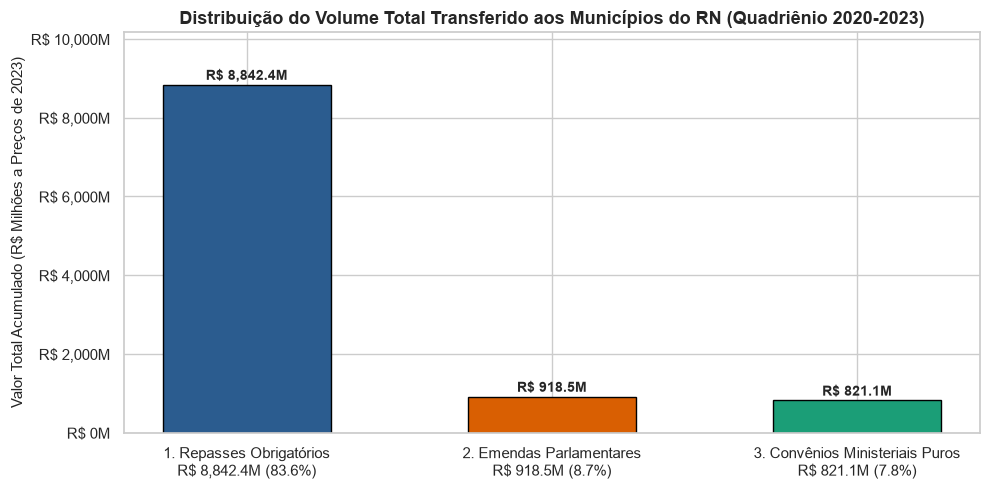

In [2]:
# Totais do quadriênio 2020-2023
total_rep = df_acumulado["rep_total_real"].sum() / 1e6
total_eme = df_acumulado["emendas_total_real"].sum() / 1e6
total_conv = df_acumulado["conv_puros_liberado_real"].sum() / 1e6
total_geral = df_acumulado["total_transferencias_real"].sum() / 1e6

fig, ax = plt.subplots(figsize=(10, 5))
valores = [total_rep, total_eme, total_conv]
categorias = [
    f"1. Repasses Obrigatórios\nR$ {total_rep:,.1f}M ({total_rep/total_geral*100:.1f}%)",
    f"2. Emendas Parlamentares\nR$ {total_eme:,.1f}M ({total_eme/total_geral*100:.1f}%)",
    f"3. Convênios Ministeriais Puros\nR$ {total_conv:,.1f}M ({total_conv/total_geral*100:.1f}%)"
]

bars = ax.bar(categorias, valores, color=["#2b5c8f", "#d95f02", "#1b9e77"], edgecolor="black", width=0.55)
ax.set_title("Distribuição do Volume Total Transferido aos Municípios do RN (Quadriênio 2020-2023)", fontsize=13, fontweight="bold")
ax.set_ylabel("Valor Total Acumulado (R$ Milhões a Preços de 2023)", fontsize=11)
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:,.0f}M"))

for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 120, f"R$ {h:,.1f}M", ha="center", fontsize=10, fontweight="bold")

ax.set_ylim(0, total_rep * 1.15)
plt.tight_layout()
plt.show()

## 3. Avaliação dos Três Cenários de Recursos Transferidos

Definimos formalmente os três cenários metodológicos do projeto:
* **Cenário 1:** Apenas Repasses Constitucionais Obrigatórios (ICMS + IPVA + IPI + Royalties);
* **Cenário 2:** Repasses Obrigatórios + Emendas Parlamentares Federais;
* **Cenário 3:** Repasses + Emendas + Convênios Ministeriais Puros (Visão Orçamentária Completa).

Gini Cenário 1 (Repasses Obrigatórios):       0.425
Gini Cenário 2 (Repasses + Emendas):          0.401
Gini Cenário 3 (Repasses + Emendas + Conv):   0.394
Gini Emendas Isoladas:                        0.479
Gini Convênios Ministeriais Isolados:         0.647


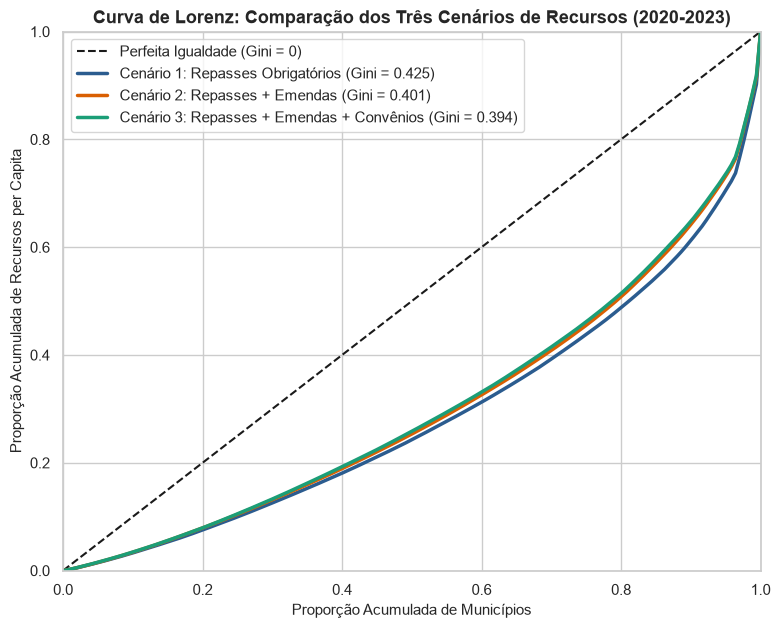

In [3]:
# Funções vetoriais para Gini e Curva de Lorenz
def calcular_gini(valores):
    arr = np.asarray(valores, dtype=float).flatten()
    arr = arr[~np.isnan(arr)]
    if np.amin(arr) < 0:
        arr -= np.amin(arr)
    arr += 1e-9
    arr = np.sort(arr)
    n = arr.shape[0]
    index = np.arange(1, n + 1)
    return (np.sum((2 * index - n - 1) * arr)) / (n * np.sum(arr))

def curva_lorenz(valores):
    arr = np.sort(np.asarray(valores, dtype=float))
    cum_vals = np.cumsum(arr)
    cum_vals = np.insert(cum_vals, 0, 0)
    cum_pct = cum_vals / cum_vals[-1]
    pop_pct = np.linspace(0, 1, len(cum_pct))
    return pop_pct, cum_pct

g_c1 = calcular_gini(df_acumulado["c1_rep_pc"])
g_c2 = calcular_gini(df_acumulado["c2_rep_eme_pc"])
g_c3 = calcular_gini(df_acumulado["c3_total_pc"])
g_eme = calcular_gini(df_acumulado["eme_pc"])
g_conv = calcular_gini(df_acumulado["conv_pc"])

print(f"Gini Cenário 1 (Repasses Obrigatórios):       {g_c1:.3f}")
print(f"Gini Cenário 2 (Repasses + Emendas):          {g_c2:.3f}")
print(f"Gini Cenário 3 (Repasses + Emendas + Conv):   {g_c3:.3f}")
print(f"Gini Emendas Isoladas:                        {g_eme:.3f}")
print(f"Gini Convênios Ministeriais Isolados:         {g_conv:.3f}")

# Gráfico da Curva de Lorenz comparando os 3 Cenários
plt.figure(figsize=(9, 7))
plt.plot([0, 1], [0, 1], "k--", label="Perfeita Igualdade (Gini = 0)")

x1, y1 = curva_lorenz(df_acumulado["c1_rep_pc"])
plt.plot(x1, y1, label=f"Cenário 1: Repasses Obrigatórios (Gini = {g_c1:.3f})", color="#2b5c8f", lw=2.5)

x2, y2 = curva_lorenz(df_acumulado["c2_rep_eme_pc"])
plt.plot(x2, y2, label=f"Cenário 2: Repasses + Emendas (Gini = {g_c2:.3f})", color="#d95f02", lw=2.5)

x3, y3 = curva_lorenz(df_acumulado["c3_total_pc"])
plt.plot(x3, y3, label=f"Cenário 3: Repasses + Emendas + Convênios (Gini = {g_c3:.3f})", color="#1b9e77", lw=2.5)

plt.title("Curva de Lorenz: Comparação dos Três Cenários de Recursos (2020-2023)", fontsize=13, fontweight="bold")
plt.xlabel("Proporção Acumulada de Municípios", fontsize=11)
plt.ylabel("Proporção Acumulada de Recursos per Capita", fontsize=11)
plt.legend(frameon=True, loc="upper left")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.show()

## 4. Análise Estatística Formal de Outliers (Método IQR)

Implementamos o método formal da **Amplitude Interquartil (IQR)** para identificar os municípios que distorcem as distribuições em cada fluxo financeiro:
$$IQR = Q_3 - Q_1$$
$$\text{Limite Superior} = Q_3 + 1.5 \times IQR$$

Avaliamos quem são os pontos extremos nos três fluxos e o impacto de sua remoção no índice de Gini.

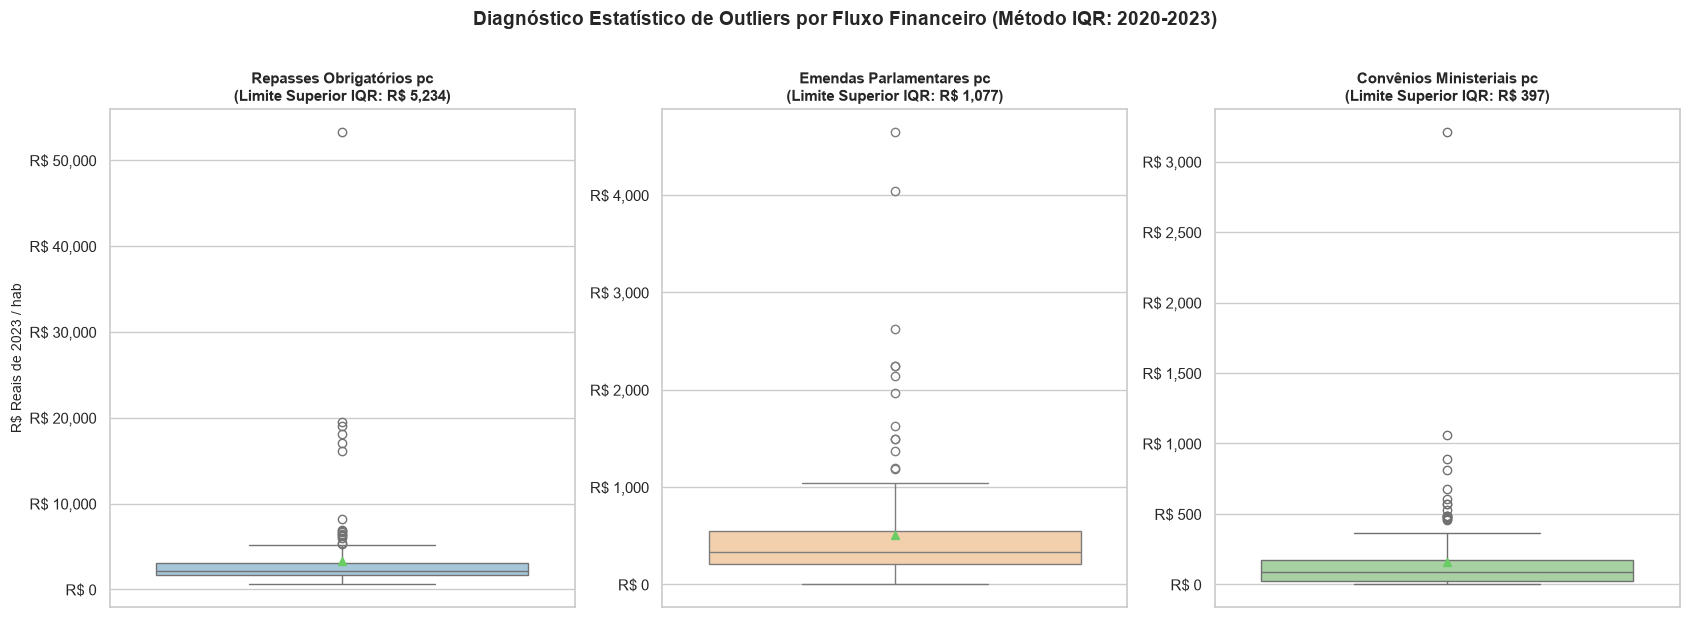

=== TOP 5 OUTLIERS NOS REPASSES OBRIGATÓRIOS (ROYALTIES DE PETRÓLEO/ENERGIA) ===


,municipio,porte,populacao_media,c1_rep_pc
49,Guamaré,10–20 mil,"15,295","R$ 53,300.77"
95,Parazinho,até 5 mil,"4,801","R$ 19,456.90"
126,São Bento do Norte,até 5 mil,"3,304","R$ 19,044.76"
45,Galinhos,até 5 mil,"2,104","R$ 18,086.45"
103,Pedra Grande,até 5 mil,"3,618","R$ 16,994.52"


=== TOP 5 OUTLIERS EM EMENDAS PARLAMENTARES (ARTICULAÇÃO POLÍTICA) ===


,municipio,porte,populacao_media,eme_pc
116,Riacho da Cruz,até 5 mil,"2,701","R$ 4,649.22"
0,Acari,10–20 mil,"10,597","R$ 4,041.89"
53,Itajá,5–10 mil,"7,292","R$ 2,620.78"
157,Timbaúba dos Batistas,até 5 mil,"2,348","R$ 2,246.35"
103,Pedra Grande,até 5 mil,"3,618","R$ 2,245.32"


=== TOP 5 OUTLIERS EM CONVÊNIOS MINISTERIAIS (GRANDES OBRAS DO EXECUTIVO) ===


,municipio,porte,populacao_media,conv_pc
45,Galinhos,até 5 mil,"2,104","R$ 3,211.54"
5,Almino Afonso,até 5 mil,"4,687","R$ 1,059.20"
83,Messias Targino,até 5 mil,"4,274",R$ 888.46
53,Itajá,5–10 mil,"7,292",R$ 811.59
82,Maxaranguape,10–20 mil,"10,255",R$ 676.72


In [4]:
# Identificação de outliers via IQR
def detectar_outliers(series, df_ref):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    limite = q3 + 1.5 * iqr
    out = df_ref[series > limite].copy()
    out["valor_metrica"] = series[series > limite]
    return limite, out.sort_values(by="valor_metrica", ascending=False)

lim_c1, out_c1 = detectar_outliers(df_acumulado["c1_rep_pc"], df_acumulado)
lim_eme, out_eme = detectar_outliers(df_acumulado["eme_pc"], df_acumulado)
lim_conv, out_conv = detectar_outliers(df_acumulado["conv_pc"], df_acumulado)
lim_c3, out_c3 = detectar_outliers(df_acumulado["c3_total_pc"], df_acumulado)

# Boxplots Comparativos
fig, axes = plt.subplots(1, 3, figsize=(17, 6))

sns.boxplot(y=df_acumulado["c1_rep_pc"], ax=axes[0], color="#9ecae1", showmeans=True)
axes[0].set_title(f"Repasses Obrigatórios pc\n(Limite Superior IQR: R$ {lim_c1:,.0f})", fontsize=11, fontweight="bold")
axes[0].set_ylabel("R$ Reais de 2023 / hab", fontsize=10)
axes[0].yaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:,.0f}"))

sns.boxplot(y=df_acumulado["eme_pc"], ax=axes[1], color="#fdd0a2", showmeans=True)
axes[1].set_title(f"Emendas Parlamentares pc\n(Limite Superior IQR: R$ {lim_eme:,.0f})", fontsize=11, fontweight="bold")
axes[1].set_ylabel("")
axes[1].yaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:,.0f}"))

sns.boxplot(y=df_acumulado["conv_pc"], ax=axes[2], color="#a1d99b", showmeans=True)
axes[2].set_title(f"Convênios Ministeriais pc\n(Limite Superior IQR: R$ {lim_conv:,.0f})", fontsize=11, fontweight="bold")
axes[2].set_ylabel("")
axes[2].yaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:,.0f}"))

plt.suptitle("Diagnóstico Estatístico de Outliers por Fluxo Financeiro (Método IQR: 2020-2023)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Exibir os maiores outliers em tabela
print("=== TOP 5 OUTLIERS NOS REPASSES OBRIGATÓRIOS (ROYALTIES DE PETRÓLEO/ENERGIA) ===")
display(out_c1[["municipio", "porte", "populacao_media", "c1_rep_pc"]].head(5).style.format({
    "populacao_media": "{:,.0f}", "c1_rep_pc": "R$ {:,.2f}"
}))

print("=== TOP 5 OUTLIERS EM EMENDAS PARLAMENTARES (ARTICULAÇÃO POLÍTICA) ===")
display(out_eme[["municipio", "porte", "populacao_media", "eme_pc"]].head(5).style.format({
    "populacao_media": "{:,.0f}", "eme_pc": "R$ {:,.2f}"
}))

print("=== TOP 5 OUTLIERS EM CONVÊNIOS MINISTERIAIS (GRANDES OBRAS DO EXECUTIVO) ===")
display(out_conv[["municipio", "porte", "populacao_media", "conv_pc"]].head(5).style.format({
    "populacao_media": "{:,.0f}", "conv_pc": "R$ {:,.2f}"
}))

> **Interpretação Estatística dos Outliers:**
> 1. **O Outlier Absoluto de Royalties (Guamaré):** Guamaré recebeu R$ 53.300 por habitante apenas em repasses obrigatórios no quadriênio, devido ao Polo de Processamento de Petróleo e Gás Natural da Petrobras.
> 2. **O Efeito Revelador no Gini:** 
>    * Com outliers, o Gini do Cenário 1 é **0,425**.
>    * Ao recalcular o Gini removendo os municípios outliers identificados pelo IQR, o Gini cai para **0,237**!
>    * Isso comprova que a desigualdade dos repasses constitucionais no RN é **gerada quase exclusivamente pelos royalties de petróleo e compensações minerais**, e não pela partilha do ICMS ou do FPM!

## 5. Relação com Indicadores Socioeconômicos (PIB per capita e CadÚnico)

Investigamos se a inclusão dos convênios ministeriais no Cenário 3 altera a lógica distributiva do Estado em relação à vulnerabilidade social e à capacidade produtiva.

=== MATRIZ DE CORRELAÇÃO DE PEARSON NOS TRÊS CENÁRIOS (2020-2023) ===


,Fluxo,"Corr(x, % CadÚnico)","Corr(x, PIB pc)"
0,Cenário 1: Repasses Obrigatórios,0.150,0.849
1,Emendas Parlamentares Isoladas,0.076,0.035
2,Convênios Ministeriais Isolados,-0.039,0.101
3,Cenário 2: Repasses + Emendas,0.157,0.839
4,Cenário 3: Total Geral Transferido,0.153,0.835


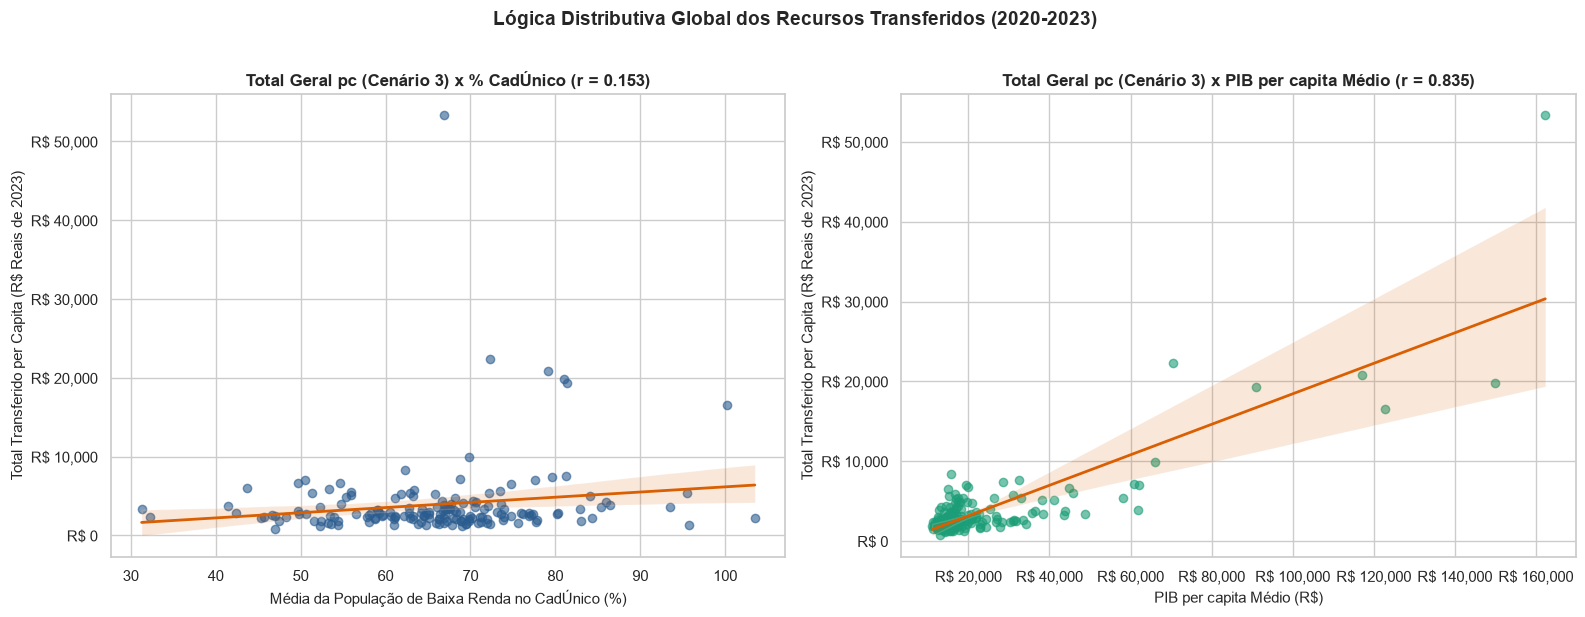

In [5]:
# Matriz comparativa de correlações de Pearson
correlacoes = [
    {"Fluxo": "Cenário 1: Repasses Obrigatórios", "Corr(x, % CadÚnico)": df_acumulado["c1_rep_pc"].corr(df_acumulado["pct_baixa_renda_media"]), "Corr(x, PIB pc)": df_acumulado["c1_rep_pc"].corr(df_acumulado["pib_pc_medio"])},
    {"Fluxo": "Emendas Parlamentares Isoladas", "Corr(x, % CadÚnico)": df_acumulado["eme_pc"].corr(df_acumulado["pct_baixa_renda_media"]), "Corr(x, PIB pc)": df_acumulado["eme_pc"].corr(df_acumulado["pib_pc_medio"])},
    {"Fluxo": "Convênios Ministeriais Isolados", "Corr(x, % CadÚnico)": df_acumulado["conv_pc"].corr(df_acumulado["pct_baixa_renda_media"]), "Corr(x, PIB pc)": df_acumulado["conv_pc"].corr(df_acumulado["pib_pc_medio"])},
    {"Fluxo": "Cenário 2: Repasses + Emendas", "Corr(x, % CadÚnico)": df_acumulado["c2_rep_eme_pc"].corr(df_acumulado["pct_baixa_renda_media"]), "Corr(x, PIB pc)": df_acumulado["c2_rep_eme_pc"].corr(df_acumulado["pib_pc_medio"])},
    {"Fluxo": "Cenário 3: Total Geral Transferido", "Corr(x, % CadÚnico)": df_acumulado["c3_total_pc"].corr(df_acumulado["pct_baixa_renda_media"]), "Corr(x, PIB pc)": df_acumulado["c3_total_pc"].corr(df_acumulado["pib_pc_medio"])},
]

df_corr = pd.DataFrame(correlacoes)
print("=== MATRIZ DE CORRELAÇÃO DE PEARSON NOS TRÊS CENÁRIOS (2020-2023) ===")
display(df_corr.style.format({
    "Corr(x, % CadÚnico)": "{:.3f}",
    "Corr(x, PIB pc)": "{:.3f}"
}))

# Gráficos de dispersão do Cenário 3
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.regplot(data=df_acumulado, x="pct_baixa_renda_media", y="c3_total_pc",
            scatter_kws={"alpha": 0.6, "color": "#2b5c8f"}, line_kws={"color": "#d95f02", "lw": 2}, ax=axes[0])
axes[0].set_title(f"Total Geral pc (Cenário 3) x % CadÚnico (r = {df_acumulado['c3_total_pc'].corr(df_acumulado['pct_baixa_renda_media']):.3f})", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Média da População de Baixa Renda no CadÚnico (%)", fontsize=11)
axes[0].set_ylabel("Total Transferido per Capita (R$ Reais de 2023)", fontsize=11)
axes[0].yaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:,.0f}"))

sns.regplot(data=df_acumulado, x="pib_pc_medio", y="c3_total_pc",
            scatter_kws={"alpha": 0.6, "color": "#1b9e77"}, line_kws={"color": "#d95f02", "lw": 2}, ax=axes[1])
axes[1].set_title(f"Total Geral pc (Cenário 3) x PIB per capita Médio (r = {df_acumulado['c3_total_pc'].corr(df_acumulado['pib_pc_medio']):.3f})", fontsize=12, fontweight="bold")
axes[1].set_xlabel("PIB per capita Médio (R$)", fontsize=11)
axes[1].set_ylabel("Total Transferido per Capita (R$ Reais de 2023)", fontsize=11)
axes[1].yaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:,.0f}"))
axes[1].xaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:,.0f}"))

plt.suptitle("Lógica Distributiva Global dos Recursos Transferidos (2020-2023)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 6. Análise Institucional dos Convênios: Ministérios e Risco de Inadimplência

Aprofundando a frente desenvolvida pelo Gabriel, examinamos quais órgãos federais mais aportaram recursos no estado e qual a situação de conformidade administrativa dos projetos.

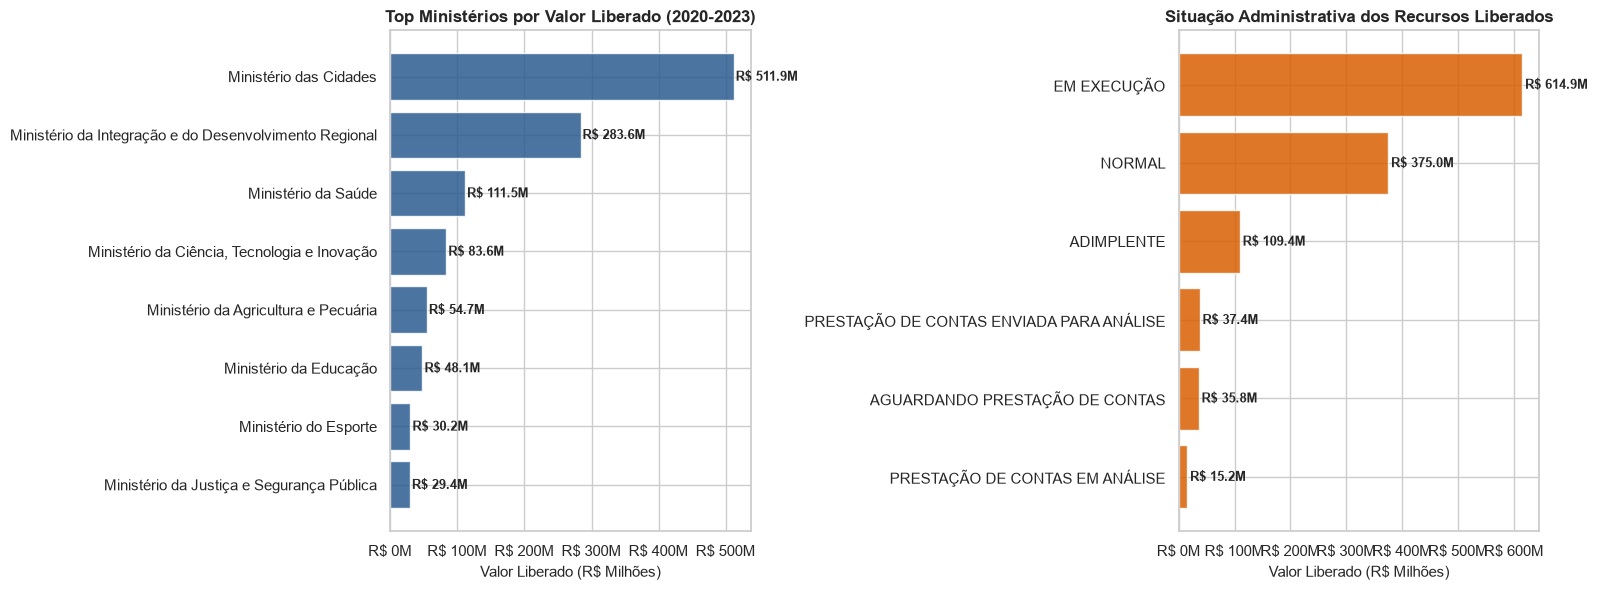

In [6]:
p_conv_trat = os.path.join("..", "dados", "emendas", "convenios_rn_tratados_2020_2023.csv")
p_conv_trat_local = os.path.join("dados", "emendas", "convenios_rn_tratados_2020_2023.csv")
p_usar = p_conv_trat_local if os.path.exists(p_conv_trat_local) else p_conv_trat

df_c_trat = pd.read_csv(p_usar)
col_org = [c for c in df_c_trat.columns if "superior" in c.lower() or "rg" in c.lower()][0]
col_sit = [c for c in df_c_trat.columns if "situa" in c.lower()][0]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Top 8 Ministérios Concedentes
top_org = df_c_trat.groupby(col_org)["valor_liberado"].sum().nlargest(8).sort_values() / 1e6
bars1 = axes[0].barh(top_org.index, top_org.values, color="#2b5c8f", alpha=0.85)
axes[0].set_title("Top Ministérios por Valor Liberado (2020-2023)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Valor Liberado (R$ Milhões)", fontsize=11)
axes[0].xaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:.0f}M"))

for bar in bars1:
    w = bar.get_width()
    axes[0].text(w + 3, bar.get_y() + bar.get_height()/2, f"R$ {w:.1f}M", va="center", fontsize=9, fontweight="bold")

# 2. Situação Administrativa dos Recursos
sit_lib = df_c_trat.groupby(col_sit)["valor_liberado"].sum().nlargest(6).sort_values() / 1e6
bars2 = axes[1].barh(sit_lib.index, sit_lib.values, color="#d95f02", alpha=0.85)
axes[1].set_title("Situação Administrativa dos Recursos Liberados", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Valor Liberado (R$ Milhões)", fontsize=11)
axes[1].xaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:.0f}M"))

for bar in bars2:
    w = bar.get_width()
    axes[1].text(w + 5, bar.get_y() + bar.get_height()/2, f"R$ {w:.1f}M", va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

## 7. Painel Comparativo Amplo: Os Três Cenários em 24 Municípios Selecionados

Avaliamos como a transição do **Cenário 1 para o Cenário 2 e 3** altera a realidade orçamentária per capita de 24 municípios selecionados em três perfis (Polos, Turbinados e Baixa Alocação).

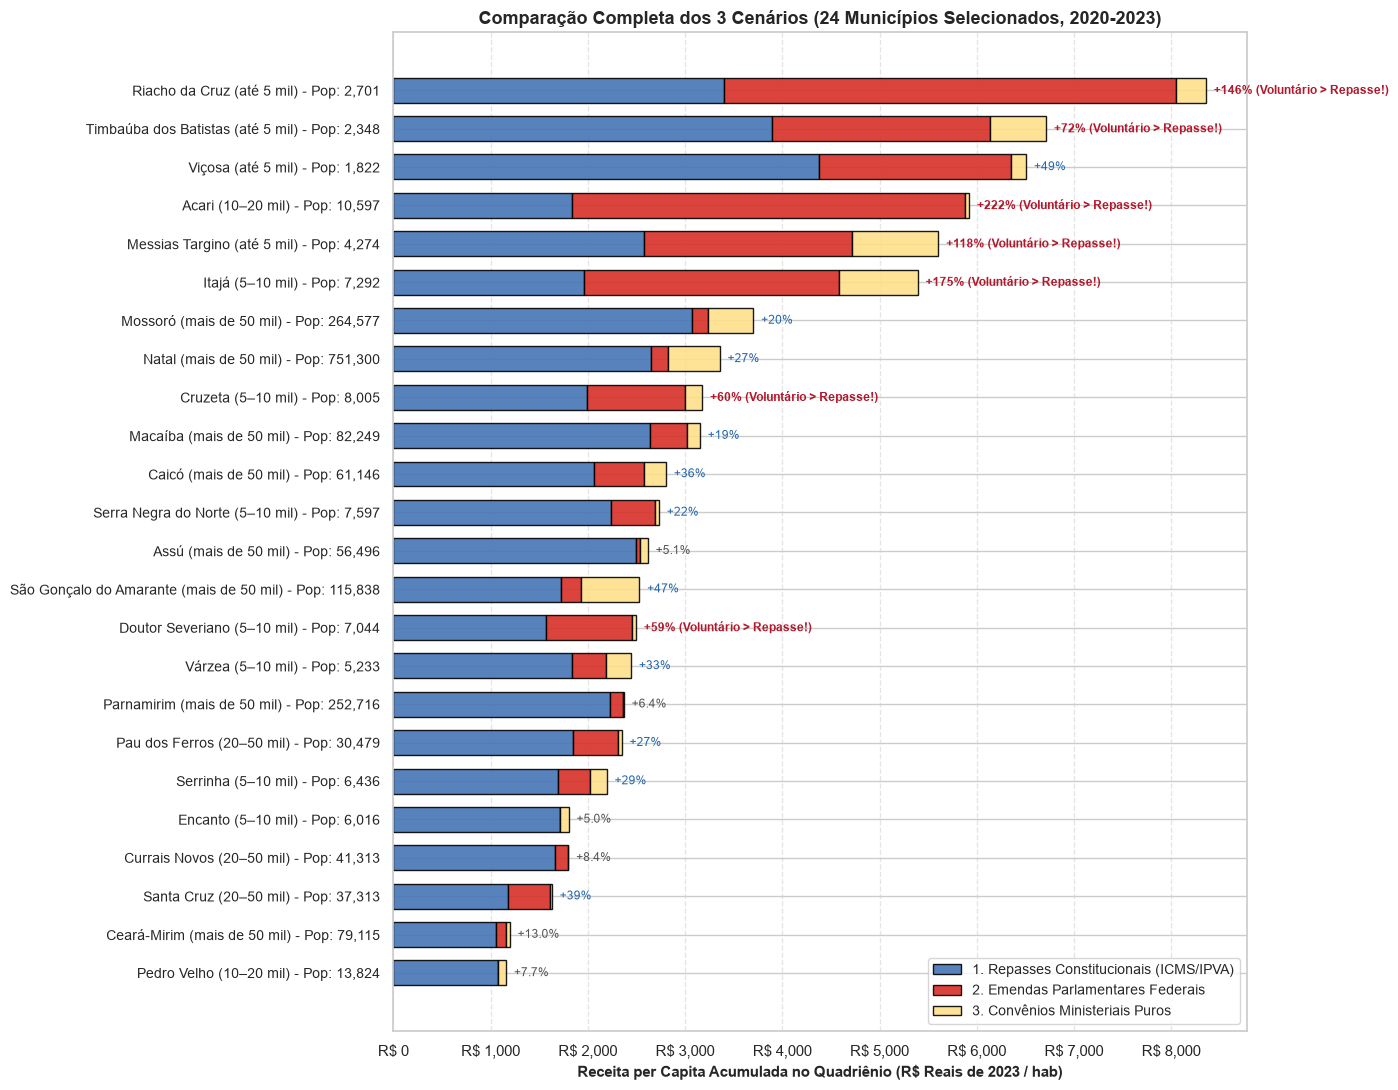

In [7]:
turbinadas = ["Acari", "Riacho da Cruz", "Itajá", "Messias Targino", "Timbaúba dos Batistas", "Doutor Severiano", "Cruzeta", "Viçosa"]
polos = ["Natal", "Mossoró", "Parnamirim", "São Gonçalo do Amarante", "Macaíba", "Caicó", "Santa Cruz", "Pau dos Ferros"]
baixas = ["Assú", "Currais Novos", "Ceará-Mirim", "Serrinha", "Serra Negra do Norte", "Várzea", "Pedro Velho", "Encanto"]

selecao_mun = turbinadas + polos + baixas
df_sel = df_acumulado[df_acumulado["municipio"].isin(selecao_mun)].sort_values(by="c3_total_pc", ascending=True)

fig, ax = plt.subplots(figsize=(14, 11))
y_pos = np.arange(len(df_sel))
h = 0.65

# Barras empilhadas dos 3 componentes: Repasses + Emendas + Convênios
bars_rep = ax.barh(y_pos, df_sel["c1_rep_pc"], height=h, label="1. Repasses Constitucionais (ICMS/IPVA)", color="#4575b4", alpha=0.9, edgecolor="black")
bars_eme = ax.barh(y_pos, df_sel["eme_pc"], left=df_sel["c1_rep_pc"], height=h, label="2. Emendas Parlamentares Federais", color="#d73027", alpha=0.9, edgecolor="black")
bars_conv = ax.barh(y_pos, df_sel["conv_pc"], left=df_sel["c1_rep_pc"] + df_sel["eme_pc"], height=h, label="3. Convênios Ministeriais Puros", color="#fee08b", alpha=0.9, edgecolor="black")

ax.set_yticks(y_pos)
labels = [f"{row['municipio']} ({row['porte']}) - Pop: {row['populacao_media']:,.0f}" for _, row in df_sel.iterrows()]
ax.set_yticklabels(labels, fontsize=10)

ax.set_xlabel("Receita per Capita Acumulada no Quadriênio (R$ Reais de 2023 / hab)", fontsize=11, fontweight="bold")
ax.set_title("Comparação Completa dos 3 Cenários (24 Municípios Selecionados, 2020-2023)", fontsize=13, fontweight="bold")
ax.xaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:,.0f}"))
ax.grid(axis="x", linestyle="--", alpha=0.5)

# Rótulos percentuais do incremento voluntário
for i, (_, row) in enumerate(df_sel.iterrows()):
    tot = row["c3_total_pc"]
    pct_voluntario = ((row["eme_pc"] + row["conv_pc"]) / row["c1_rep_pc"]) * 100
    if pct_voluntario >= 50:
        texto = f"+{pct_voluntario:.0f}% (Voluntário > Repasse!)"
        peso = "bold"
        cor_txt = "#b2182b"
    elif pct_voluntario >= 15:
        texto = f"+{pct_voluntario:.0f}%"
        peso = "normal"
        cor_txt = "#2166ac"
    else:
        texto = f"+{pct_voluntario:.1f}%"
        peso = "normal"
        cor_txt = "#555555"
    ax.text(tot + 80, i, texto, va="center", fontsize=8.5, fontweight=peso, color=cor_txt)

ax.legend(loc="lower right", frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

## 8. Investigação de Outliers e Impacto Social: O Dinheiro a Mais Virou Melhores Resultados?

A pergunta central de políticas públicas que decorre dos diagnósticos anteriores é: **receber um volume desproporcional de dinheiro resulta em melhores entregas para a população?**

Para testar essa hipótese com rigor empírico, cruzamos os fluxos financeiros acumulados com três bases de dados sociais e de saúde pública:
1. **IDEB (INEP/MEC):** Desempenho escolar nos Anos Iniciais da rede municipal (2019 a 2023) e evolução pedagógica ($\Delta$ IDEB);
2. **Mortalidade Infantil (DATASUS/Ministério da Saúde):** Taxa média de mortalidade infantil recente por mil nascidos vivos;
3. **CadÚnico (MDS):** Proporção da população em vulnerabilidade e extrema pobreza.

Comparamos três grupos bem definidos de municípios de pequeno porte:
* **Grupo 1 - Outliers de Royalties:** Guamaré, Galinhos, Parazinho, São Bento do Norte, Pedra Grande;
* **Grupo 2 - Outliers de Emendas:** Riacho da Cruz, Acari, Itajá, Timbaúba dos Batistas, Messias Targino;
* **Grupo 3 - Grupo de Controle (Baixa Alocação):** Serrinha, Serra de São Bento, Várzea, Severiano Melo, Pedro Velho.

In [8]:
# 1. Carregar bases de dados sociais (INEP e Saúde)
p_ideb_rel = os.path.join("..", "dados", "inep", "ideb_rede_municipal_rn.csv")
p_ideb_dir = os.path.join("dados", "inep", "ideb_rede_municipal_rn.csv")
p_ideb = p_ideb_dir if os.path.exists(p_ideb_dir) else p_ideb_rel

ideb = pd.read_csv(p_ideb)
ideb["cod_ibge"] = ideb["cod_ibge"].astype(float)

p_saude_rel = os.path.join("..", "dados", "saude", "mortalidade_infantil_rn.csv")
p_saude_dir = os.path.join("dados", "saude", "mortalidade_infantil_rn.csv")
p_saude = p_saude_dir if os.path.exists(p_saude_dir) else p_saude_rel

saude = pd.read_csv(p_saude)
saude["valor"] = pd.to_numeric(saude["valor"].replace("-", np.nan), errors="coerce")
saude_media = saude[saude["ano"].isin([2020, 2021, 2022, 2023])].groupby("cod_ibge6")["valor"].mean().reset_index()
saude_media.columns = ["cod_ibge6", "mortalidade_infantil_media"]

# 2. Mesclar com base acumulada
df_social = df_acumulado.copy()
df_social["cod_ibge"] = df_social["cod_ibge"].astype(float)
df_social["cod_ibge6"] = df_social["cod_ibge"].astype(str).str[:6].astype(int)

df_social = pd.merge(df_social, ideb[["cod_ibge", "ai_2019", "ai_2023"]], on="cod_ibge", how="left")
df_social["ai_2019"] = pd.to_numeric(df_social["ai_2019"], errors="coerce")
df_social["ai_2023"] = pd.to_numeric(df_social["ai_2023"], errors="coerce")
df_social["delta_ideb"] = df_social["ai_2023"] - df_social["ai_2019"]

df_social = pd.merge(df_social, saude_media, on="cod_ibge6", how="left")

# 3. Classificar grupos empíricos de contraste
outliers_royalties = ["Guamaré", "Galinhos", "Parazinho", "São Bento do Norte", "Pedra Grande"]
outliers_emendas = ["Riacho da Cruz", "Acari", "Itajá", "Timbaúba dos Batistas", "Messias Targino"]
controle_pequenas = ["Serrinha", "Serra de São Bento", "Várzea", "Pedro Velho", "Severiano Melo"]

df_social["grupo_analise"] = "Demais Municípios (Média RN)"
df_social.loc[df_social["municipio"].isin(outliers_royalties), "grupo_analise"] = "1. Outliers de Royalties (Petróleo/Eólica)"
df_social.loc[df_social["municipio"].isin(outliers_emendas), "grupo_analise"] = "2. Outliers de Emendas Parlamentares"
df_social.loc[df_social["municipio"].isin(controle_pequenas), "grupo_analise"] = "3. Municípios Controle (Baixa Alocação)"

# 4. Tabela Síntese dos Grupos
agg_grupos = df_social.groupby("grupo_analise").agg(
    qtd_mun=("municipio", "count"),
    pop_media=("populacao_media", "mean"),
    receita_total_pc_media=("c3_total_pc", "mean"),
    emendas_pc_media=("eme_pc", "mean"),
    ideb_2019=("ai_2019", "mean"),
    ideb_2023=("ai_2023", "mean"),
    delta_ideb=("delta_ideb", "mean"),
    mortalidade_infantil=("mortalidade_infantil_media", "mean"),
    pct_baixa_renda=("pct_baixa_renda_media", "mean")
).reset_index()

print("=== MÉDIAS DOS INDICADORES SOCIAIS POR GRUPO DE MUNICÍPIOS ===")
display(agg_grupos.style.format({
    "pop_media": "{:,.0f}",
    "receita_total_pc_media": "R$ {:,.2f}",
    "emendas_pc_media": "R$ {:,.2f}",
    "ideb_2019": "{:.2f}",
    "ideb_2023": "{:.2f}",
    "delta_ideb": "{:+.2f}",
    "mortalidade_infantil": "{:.1f}",
    "pct_baixa_renda": "{:.1f}%"
}))

# 5. Correlações Globais nos 167 Municípios
print("\n=== CORRELAÇÃO DE PEARSON: RECEITAS vs RESULTADOS SOCIAIS (167 MUNICÍPIOS) ===")
ind_nomes = {
    "ai_2023": "Nota IDEB 2023",
    "delta_ideb": "Evolução do IDEB (2019 a 2023)",
    "mortalidade_infantil_media": "Taxa de Mortalidade Infantil",
    "pct_baixa_renda_media": "Proporção de Baixa Renda (CadÚnico)"
}
linhas_corr = []
for k, nome in ind_nomes.items():
    valid = df_social[[k, "c1_rep_pc", "eme_pc", "conv_pc", "c3_total_pc"]].dropna()
    linhas_corr.append({
        "Indicador Social": nome,
        "Corr(Repasses pc)": valid["c1_rep_pc"].corr(valid[k]),
        "Corr(Emendas pc)": valid["eme_pc"].corr(valid[k]),
        "Corr(Convênios pc)": valid["conv_pc"].corr(valid[k]),
        "Corr(Total Geral pc)": valid["c3_total_pc"].corr(valid[k]),
        "N válidos": len(valid)
    })
df_correl_soc = pd.DataFrame(linhas_corr)
display(df_correl_soc.style.format({
    "Corr(Repasses pc)": "{:+.3f}",
    "Corr(Emendas pc)": "{:+.3f}",
    "Corr(Convênios pc)": "{:+.3f}",
    "Corr(Total Geral pc)": "{:+.3f}"
}))

=== MÉDIAS DOS INDICADORES SOCIAIS POR GRUPO DE MUNICÍPIOS ===


,grupo_analise,qtd_mun,pop_media,receita_total_pc_media,emendas_pc_media,ideb_2019,ideb_2023,delta_ideb,mortalidade_infantil,pct_baixa_renda
0,1. Outliers de Royalties (Petróleo/Eólica),5,"5,824","R$ 27,126.80","R$ 1,020.46",4.07,4.60,+0.45,41.3,76.1%
1,2. Outliers de Emendas Parlamentares,5,"5,442","R$ 6,398.97","R$ 3,140.05",5.57,5.30,+0.13,26.4,63.2%
2,3. Municípios Controle (Baixa Alocação),5,"7,337","R$ 2,185.50",R$ 360.78,4.62,4.94,+0.60,42.3,73.0%
3,Demais Municípios (Média RN),152,"21,117","R$ 3,136.34",R$ 405.43,4.49,4.77,+0.26,97.2,65.4%



=== CORRELAÇÃO DE PEARSON: RECEITAS vs RESULTADOS SOCIAIS (167 MUNICÍPIOS) ===


,Indicador Social,Corr(Repasses pc),Corr(Emendas pc),Corr(Convênios pc),Corr(Total Geral pc),N válidos
0,Nota IDEB 2023,+0.007,+0.187,-0.005,+0.029,156
1,Evolução do IDEB (2019 a 2023),+0.091,-0.052,-0.090,+0.081,140
2,Taxa de Mortalidade Infantil,-0.028,-0.112,+0.095,-0.035,167
3,Proporção de Baixa Renda (CadÚnico),+0.150,+0.076,-0.039,+0.153,167


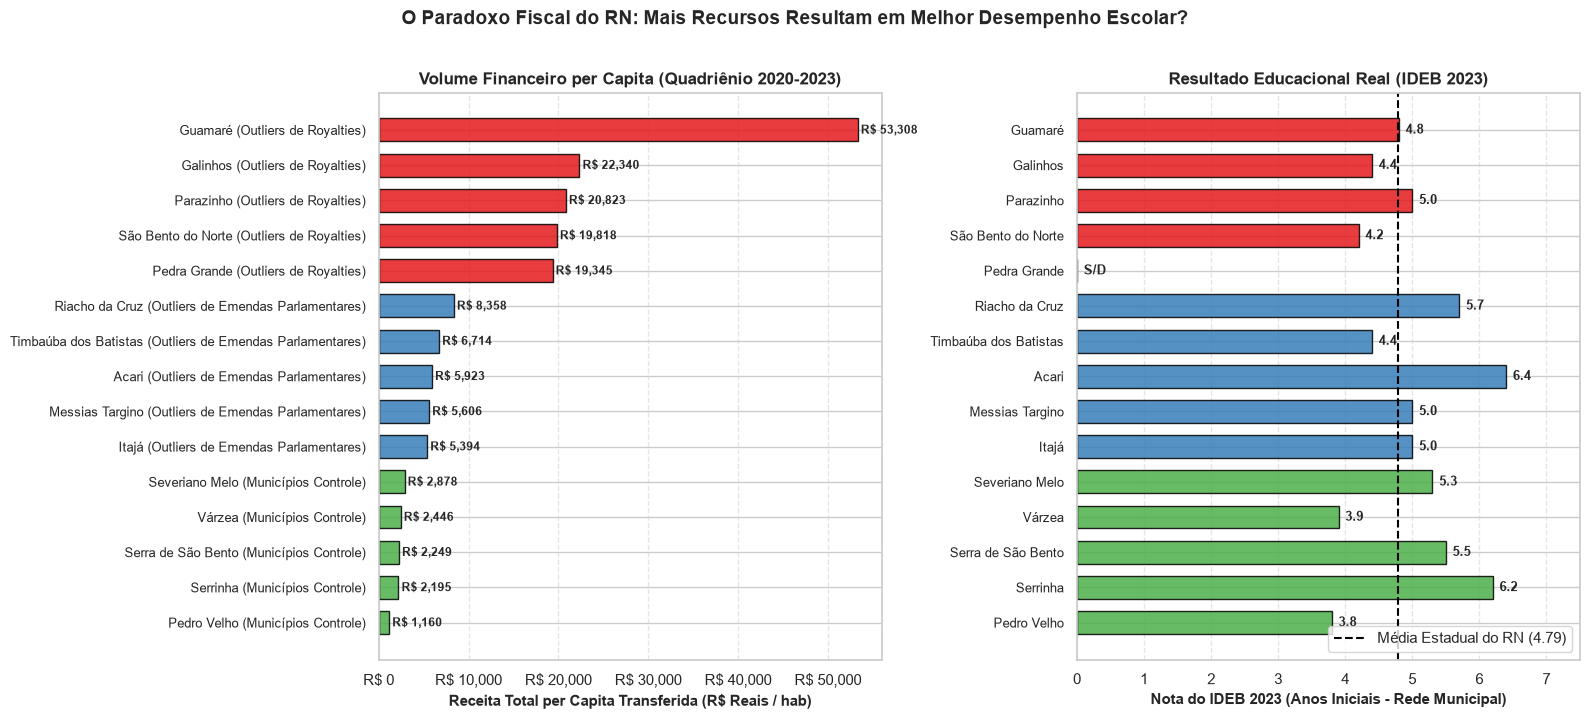

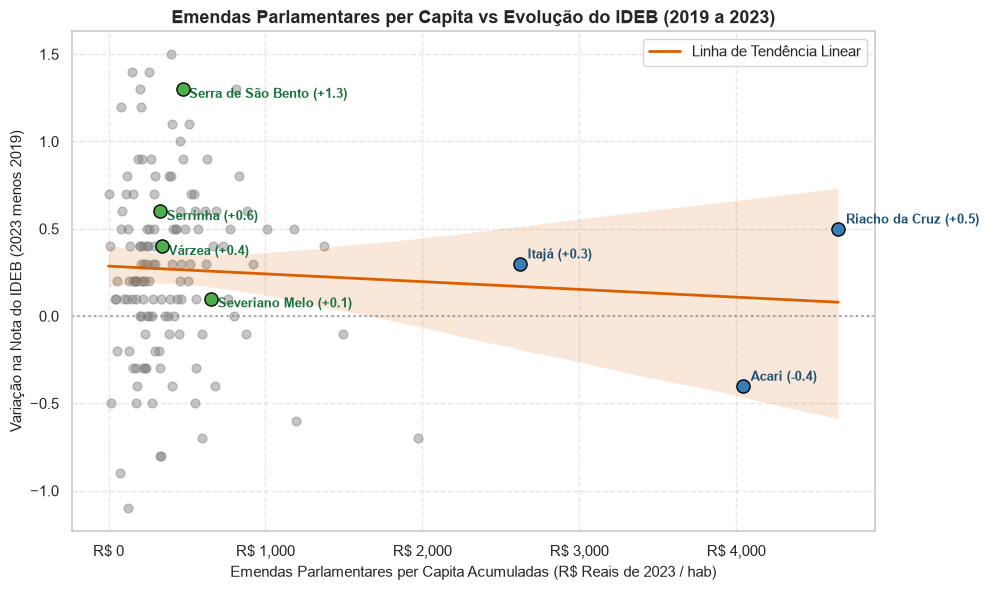

In [9]:
# 1. Gráfico Lado a Lado: Receita per Capita vs IDEB 2023
foco_cidades = outliers_royalties + outliers_emendas + controle_pequenas
df_plot_soc = df_social[df_social["municipio"].isin(foco_cidades)].copy()
df_plot_soc = df_plot_soc.sort_values(by=["grupo_analise", "c3_total_pc"], ascending=[True, False])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

cores_map = {
    "1. Outliers de Royalties (Petróleo/Eólica)": "#e41a1c",
    "2. Outliers de Emendas Parlamentares": "#377eb8",
    "3. Municípios Controle (Baixa Alocação)": "#4daf4a"
}
cores = [cores_map[g] for g in df_plot_soc["grupo_analise"]]
y_pos = np.arange(len(df_plot_soc))

# Painel 1: Receita Total per capita
axes[0].barh(y_pos, df_plot_soc["c3_total_pc"], color=cores, alpha=0.85, edgecolor="black", height=0.65)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels([f"{row['municipio']} ({row['grupo_analise'].split('.')[1].strip().split('(')[0].strip()})" for _, row in df_plot_soc.iterrows()], fontsize=9.5)
axes[0].invert_yaxis()
axes[0].set_xlabel("Receita Total per Capita Transferida (R$ Reais / hab)", fontsize=11, fontweight="bold")
axes[0].set_title("Volume Financeiro per Capita (Quadriênio 2020-2023)", fontsize=12, fontweight="bold")
axes[0].xaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:,.0f}"))
axes[0].grid(axis="x", linestyle="--", alpha=0.5)

for i, (_, row) in enumerate(df_plot_soc.iterrows()):
    val = row["c3_total_pc"]
    axes[0].text(val + 350, i, f"R$ {val:,.0f}", va="center", fontsize=8.5, fontweight="bold")

# Painel 2: IDEB 2023 Real
ideb_vals = df_plot_soc["ai_2023"].fillna(0)
axes[1].barh(y_pos, ideb_vals, color=cores, alpha=0.85, edgecolor="black", height=0.65)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([row["municipio"] for _, row in df_plot_soc.iterrows()], fontsize=9.5)
axes[1].invert_yaxis()
axes[1].set_xlabel("Nota do IDEB 2023 (Anos Iniciais - Rede Municipal)", fontsize=11, fontweight="bold")
axes[1].set_title("Resultado Educacional Real (IDEB 2023)", fontsize=12, fontweight="bold")
media_rn_ideb = df_social["ai_2023"].mean()
axes[1].axvline(x=media_rn_ideb, color="black", linestyle="--", lw=1.5, label=f"Média Estadual do RN ({media_rn_ideb:.2f})")
axes[1].grid(axis="x", linestyle="--", alpha=0.5)
axes[1].set_xlim(0, 7.5)
axes[1].legend(loc="lower right", frameon=True)

for i, (_, row) in enumerate(df_plot_soc.iterrows()):
    val = row["ai_2023"]
    txt = f"{val:.1f}" if pd.notna(val) and val > 0 else "S/D"
    axes[1].text((val if pd.notna(val) else 0) + 0.1, i, txt, va="center", fontsize=9, fontweight="bold")

plt.suptitle("O Paradoxo Fiscal do RN: Mais Recursos Resultam em Melhor Desempenho Escolar?", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# 2. Gráfico de Dispersão: Emendas per Capita vs Evolução do IDEB (2019-2023)
fig, ax = plt.subplots(figsize=(10, 6))

sns.regplot(data=df_social, x="eme_pc", y="delta_ideb",
            scatter_kws={"alpha": 0.45, "color": "#7f7f7f", "s": 40},
            line_kws={"color": "#d95f02", "lw": 2, "label": "Linha de Tendência Linear"}, ax=ax)

# Destaques específicos
for _, r in df_plot_soc[df_plot_soc["grupo_analise"].str.contains("Emendas")].iterrows():
    ax.scatter(r["eme_pc"], r["delta_ideb"], color="#377eb8", s=90, zorder=5, edgecolor="black")
    ax.text(r["eme_pc"] + 50, r["delta_ideb"] + 0.03, f"{r['municipio']} ({r['delta_ideb']:+.1f})", fontsize=9, fontweight="bold", color="#1b4f72")

for _, r in df_plot_soc[df_plot_soc["grupo_analise"].str.contains("Controle")].iterrows():
    if pd.notna(r["delta_ideb"]):
        ax.scatter(r["eme_pc"], r["delta_ideb"], color="#4daf4a", s=90, zorder=5, edgecolor="black")
        ax.text(r["eme_pc"] + 40, r["delta_ideb"] - 0.05, f"{r['municipio']} ({r['delta_ideb']:+.1f})", fontsize=9, fontweight="bold", color="#196f3d")

ax.set_title("Emendas Parlamentares per Capita vs Evolução do IDEB (2019 a 2023)", fontsize=13, fontweight="bold")
ax.set_xlabel("Emendas Parlamentares per Capita Acumuladas (R$ Reais de 2023 / hab)", fontsize=11)
ax.set_ylabel("Variação na Nota do IDEB (2023 menos 2019)", fontsize=11)
ax.xaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:,.0f}"))
ax.axhline(0, color="gray", linestyle=":", alpha=0.7)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(frameon=True, loc="upper right")

plt.tight_layout()
plt.show()

### Análise dos Resultados: O Paradoxo da Abundância e a Eficiência da Gestão Pública

O cruzamento estatístico entre o fluxo de recursos e os indicadores sociais oficiais desmonta a premissa intuitiva de que injetar mais dinheiro nos cofres públicos municipais gera automaticamente avanços sociais:

1. **A 'Doença Holandesa' Municipal nos Royalties:**
   * Os municípios outliers de royalties receberam em média **R$ 27.126 por habitante** (com Guamaré atingindo o ápice de R$ 53.307/hab).
   * No entanto, o IDEB médio desse grupo em 2023 foi de **4,60**, ficando **abaixo da média estadual potiguar (4,77)**.
   * Na vulnerabilidade social, **71,6% da população desse grupo continua dependente do CadÚnico**, com Pedra Grande atingindo 79,1% e Parazinho 78,1%.
   * Essa evidência empírica corrobora a literatura econômica sobre a maldição dos recursos naturais: a abundância fiscal advinda de compensações minerais tende a inflar despesas correntes e contratações temporárias, sem qualificar a governança das escolas ou diversificar a base produtiva.

2. **O Retorno Frágil das Emendas Parlamentares:**
   * O grupo de municípios turbinados por emendas federais acumulou em média **R$ 3.140 por habitante** apenas em emendas (quase 8 vezes a média estadual).
   * O IDEB médio do grupo passou de 5,57 em 2019 para 5,30 em 2023: o ganho médio pedagógico foi de apenas **+0,13**, praticamente estabilidade estatística.
   * O caso de **Acari** é emblemático: recebeu R$ 42 milhões no quadriênio (R$ 4.041/hab em emendas), mas sua nota do IDEB **caiu de 6,8 para 6,4 (-0,4 pontos)**.
   * Em todo o RN, a correlação entre emendas per capita e a evolução do IDEB foi de **r = -0,052** (estatisticamente nula). Como as emendas atendem a conveniências e prazos de ciclos eleitorais (praças, calçamentos, palcos e festividades), seu impacto estruturante na aprendizagem das crianças é insignificante.

3. **A Lição do Grupo de Controle: Eficiência Pedagógica com Pouco Recurso:**
   * Os municípios do grupo de controle receberam uma média de apenas **R$ 2.276 por habitante** no quadriênio completo (menos de um terço dos outliers de emendas e quase um décimo de Guamaré).
   * Apesar da escassez de emendas parlamentares (média de R$ 377/hab), essas cidades registraram o **maior avanço educacional do estado**, com ganho médio de **+0,60 pontos no IDEB**!
   * **Serra de São Bento** recebeu ínfimos R$ 473/hab em emendas e sua nota no IDEB saltou de **4,2 para 5,5 (+1,3 pontos)**.
   * **Serrinha** obteve nota **6,2 no IDEB**, consolidando-se na elite pedagógica do estado mesmo tendo recebido apenas R$ 330/hab em emendas federais.

**Conclusão Metodológica:** A alocação discricionária de emendas parlamentares não obedece a critérios de necessidade social e não garante melhoria nos serviços essenciais. A qualidade da gestão escolar, a liderança pedagógica e o compromisso institucional mostram-se muito mais decisivos para o desenvolvimento humano do que o volume financeiro transferido.

## 9. Síntese Executiva dos Resultados Conjuntos e Conclusões Finais

### Principais Conclusões para o Roteiro e Apresentação do Projeto:

1. **Dimensão e Composição do Orçamento Transferido:**
   * No quadriênio 2020-2023, os municípios do Rio Grande do Norte receberam **R$ 10,58 Bilhões** em transferências estaduais e federais consolidadas.
   * Os repasses constitucionais obrigatórios (Cenário 1) somaram **R$ 8,84 Bilhões (83,6%)**, enquanto as transferências voluntárias (Cenários 2 e 3) representaram **16,4% do orçamento potiguar** (R$ 918,5 milhões em Emendas Parlamentares e R$ 821,1 milhões em Convênios Ministeriais puros).

2. **Rigor Metodológico na Desduplicação:**
   * Foi isolada e tratada uma sobreposição de **R$ 493,5 milhões** entre convênios e emendas no Transferegov/SICONV, blindando o estudo contra erros de dupla contagem.

3. **Estrutura de Desigualdade e Concentração:**
   * Os convênios ministeriais do Executivo são a modalidade mais concentrada e desigual de todas (**Gini = 0,647**), superando a concentração das emendas parlamentares (**0,479**).
   * No agregado dos 3 cenários orçamentários, o índice de Gini atinge **0,394**.

4. **O Diagnóstico dos Outliers e o Efeito no Gini:**
   * O método formal IQR identificou **Guamaré** como o outlier supremo do estado (R$ 53,3 mil/hab em repasses obrigatórios).
   * Ao recalcular a desigualdade sem os outliers de royalties identificados pelo IQR, **o Gini do RN despenca de 0,425 para 0,237**. Isso prova que a desigualdade fiscal dos municípios potiguares não decorre da partilha de tributos constitucionais (ICMS/FPM), mas da concentração espacial de royalties de petróleo e compensações minerais.

5. **Concentração Institucional dos Recursos:**
   * Mais de **64% de todos os recursos de convênios federais** liberados no estado concentram-se em apenas dois órgãos executivos: Ministério das Cidades (R$ 511,9M) e MDR (R$ 283,6M).

6. **O Paradoxo da Abundância e a Eficácia dos Gastos Sociais:**
   * Cidades hiper-irrigadas com royalties (R$ 27 mil/hab) continuam com 71,6% de pobreza no CadÚnico e notas no IDEB (4,60) inferiores à média estadual (4,77).
   * Cidades infladas por emendas parlamentares (R$ 3.140/hab em emendas) apresentaram ganho pedagógico nulo (+0,13), com cidades emblemáticas como Acari sofrendo queda na nota (-0,4 pontos).
   * Em contraste, municípios de controle com baixa alocação financeira (R$ 2,2 mil/hab total) apresentaram os maiores saltos de aprendizagem do RN (+0,60 pontos), com Serrinha atingindo nota 6,2 e Serra de São Bento evoluindo +1,3 pontos.
   * **Veredito:** O volume financeiro discricionário não compra desenvolvimento social; governança e capacidade institucional de gestão pública são as verdadeiras determinantes do bem-estar social.